In [1]:
import pandas as pd
import os

file_path = r"C:\Users\lenovo\OneDrive\Desktop\data science\Titanic-Naive-Bayes\titanic.csv"

print(os.path.exists(file_path))

df = pd.read_csv(file_path)

df.head()

True


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
#The Titanic dataset contains information about passengers aboard the Titanic, including their age, sex, ticket class, fare, and whether they survived.
#Our main goal is to understand the data before building a machine-learning model to predict passenger survival.
#- Target variable: Survived
#- Survived = 0: Passenger did not survive.
#- Survived = 1: Passenger survived.

#Step 1: Inspect the dataset structure

# Step 1: Basic dataset inspection

print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Last 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q



Dataset shape:
(891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
#Step 2: Generate descriptive statistics

print(df.describe())

# Summary statistics for all columns

print(df.describe(include="all"))

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  
        PassengerId    Survived      Pclass                     Name   Sex  \
cou

In [4]:

# Step 3: Missing value analysis

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nPercentage of missing values:")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Total missing values:
866

Percentage of missing values:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [6]:
# Step 4: Duplicate row analysis
print("Number of duplicate rows:", df.duplicated().sum())

print("\nNumber of unique passenger IDs:", df["PassengerId"].nunique())


Number of duplicate rows: 0

Number of unique passenger IDs: 891


Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


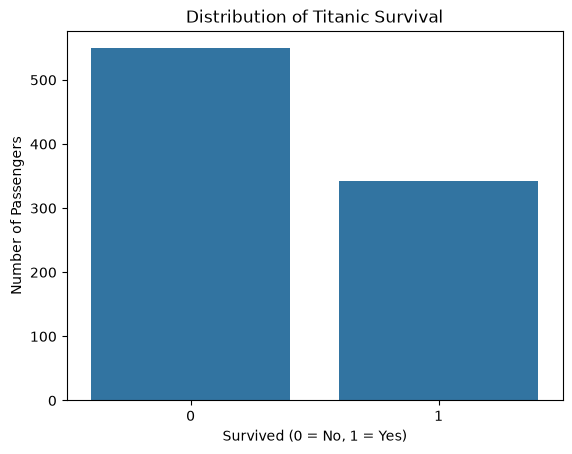

In [8]:
# Step 5: Survival class distribution
print("Survival counts:")
print(df["Survived"].value_counts().sort_index())

print("\nSurvival percentages:")
print(
    (df["Survived"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)
#visualizing it :
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Survived")

plt.title("Distribution of Titanic Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


Survived    0    1
Sex               
female     81  233
male      468  109


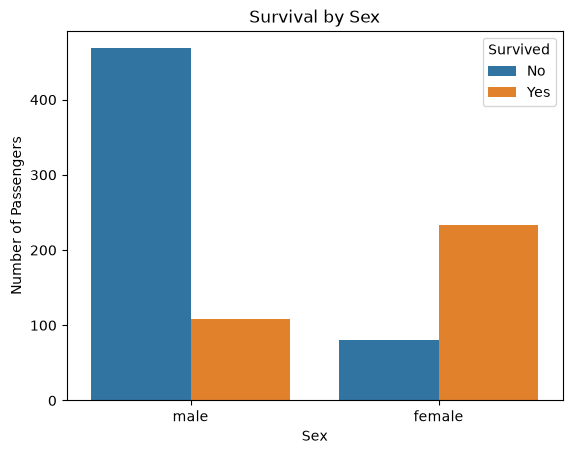

In [9]:
# Step 6: Survival by sex

print(pd.crosstab(df["Sex"], df["Survived"]))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()


Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


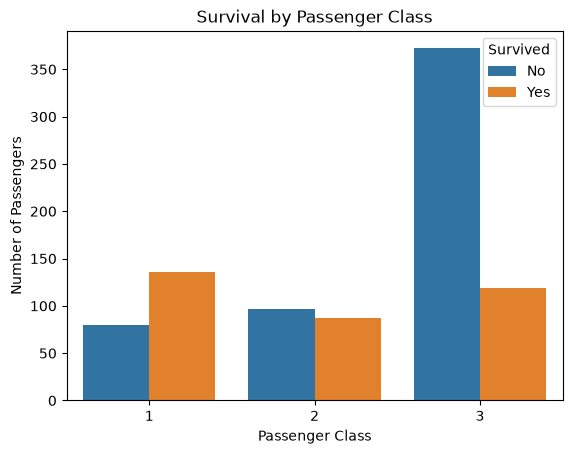

In [10]:
# Step 7: Survival by passenger class

print(pd.crosstab(df["Pclass"], df["Survived"]))

sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()


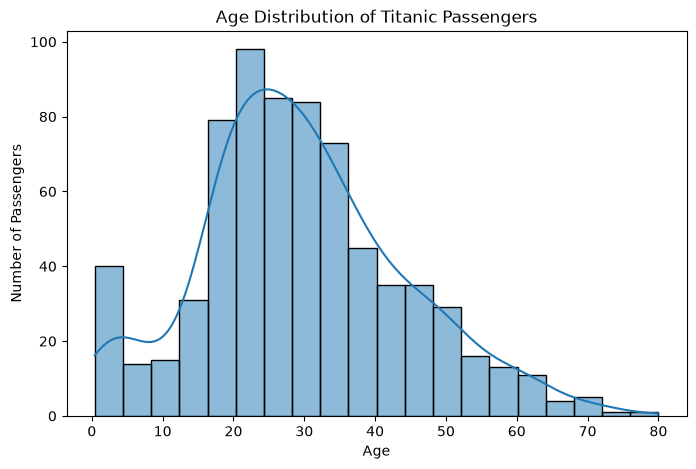

In [11]:
# Step 8: Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


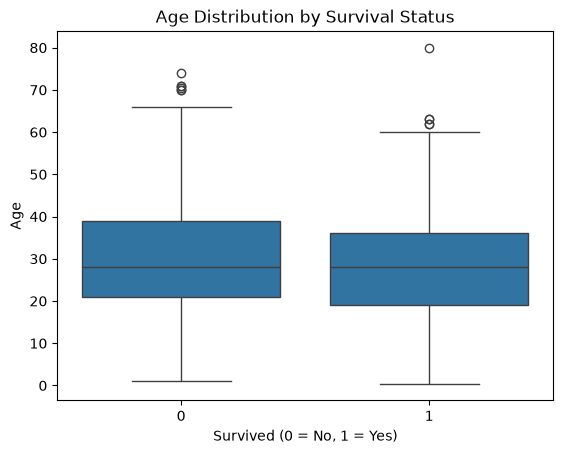

In [12]:
# Age distribution by survival

sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Distribution by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()


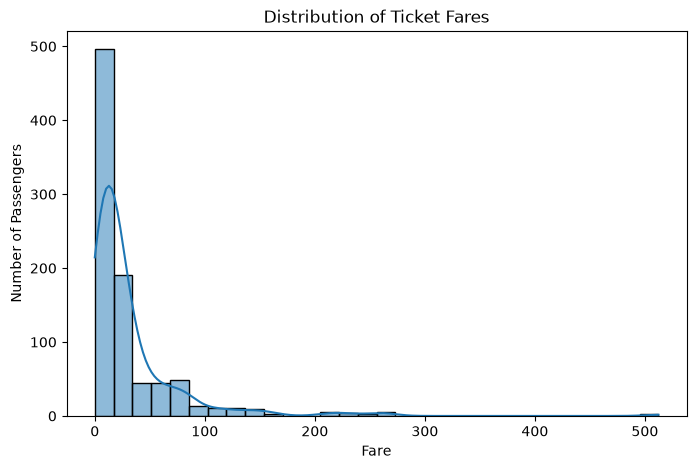

In [13]:
# Step 9: Fare distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Fare", bins=30, kde=True)

plt.title("Distribution of Ticket Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.show()


Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


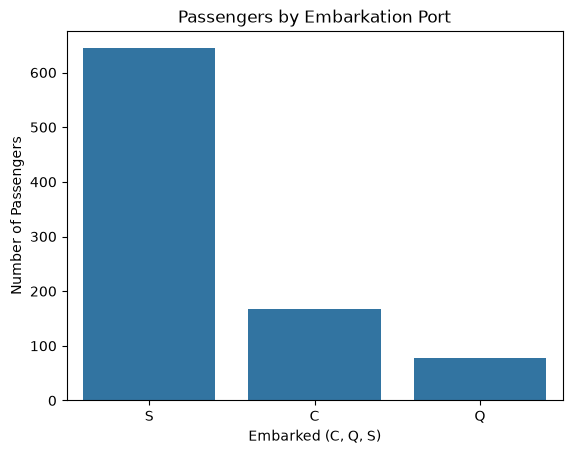

In [14]:
# Step 10: Passenger counts by embarkation port

print(df["Embarked"].value_counts(dropna=False))

sns.countplot(data=df, x="Embarked")

plt.title("Passengers by Embarkation Port")
plt.xlabel("Embarked (C, Q, S)")
plt.ylabel("Number of Passengers")
plt.show()
#The Embarked column indicates where passengers boarded the Titanic.
#C — Cherbourg
#Q — Queenstown
#S — Southampton

             PassengerId  Survived  Pclass   Age  SibSp  Parch  Fare
PassengerId         1.00     -0.01   -0.04  0.04  -0.06  -0.00  0.01
Survived           -0.01      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass             -0.04     -0.34    1.00 -0.37   0.08   0.02 -0.55
Age                 0.04     -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp              -0.06     -0.04    0.08 -0.31   1.00   0.41  0.16
Parch              -0.00      0.08    0.02 -0.19   0.41   1.00  0.22
Fare                0.01      0.26   -0.55  0.10   0.16   0.22  1.00


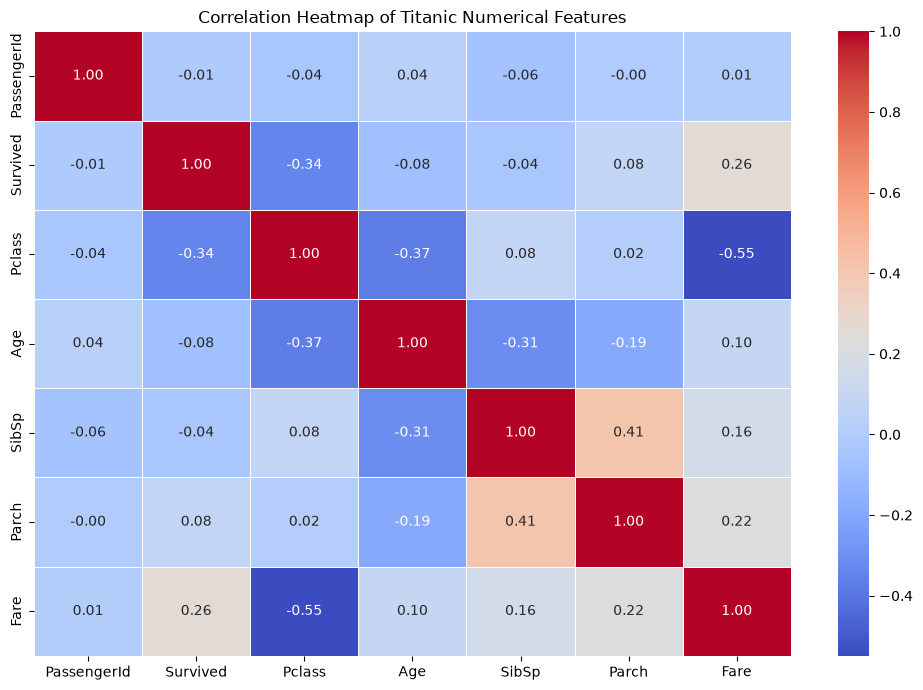

In [15]:
#Correlation measures the strength and direction of a linear relationship between numerical variables.

# Step 11: Correlation matrix

numerical_df = df.select_dtypes(include="number")

correlation = numerical_df.corr()

print(correlation.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Titanic Numerical Features")
plt.tight_layout()
plt.show()


In [16]:
# Survival rate by sex

print("Survival rate by sex (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by passenger class (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by embarkation port (%):")
print((df.groupby("Embarked")["Survived"].mean() * 100).round(2))


Survival rate by sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Survival rate by embarkation port (%):
Embarked
C    55.36
Q    38.96
S    33.70
Name: Survived, dtype: float64


Dataset shape: (891, 12)
Selected input features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Target classes: [np.int64(0), np.int64(1)]

Numerical features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Sex', 'Embarked']

Training samples: 712
Testing samples: 179

Model training completed successfully!

========== MODEL EVALUATION ==========
Accuracy: 0.7877
Accuracy percentage: 78.77 %

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.85      0.83       110
       Survived       0.74      0.70      0.72        69

       accuracy                           0.79       179
      macro avg       0.78      0.77      0.77       179
   weighted avg       0.79      0.79      0.79       179

Confusion Matrix:
[[93 17]
 [21 48]]


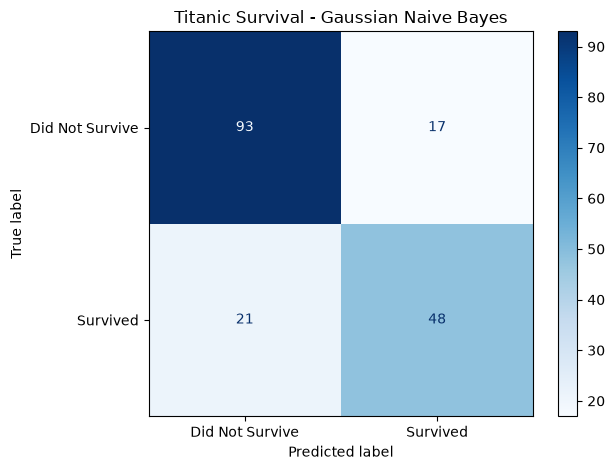

ROC-AUC Score: 0.8191

First 10 test predictions:


,Actual Survival,Predicted Survival,Survival Probability
565,0,0,0.001
160,0,0,0.007
553,1,0,0.139
860,0,0,0.001
241,1,1,0.991
559,1,1,0.888
387,1,1,0.951
536,0,0,0.053
698,0,1,0.986
99,0,0,0.012


In [18]:

# ============================================================
# TITANIC SURVIVAL PREDICTION USING GAUSSIAN NAIVE BAYES
# Complete workflow: preprocessing, training, and evaluation
# ============================================================
# Feature selection
#We predict Survived using Pclass, Sex, Age, SibSp, Parch, Fare, and Embarked.
#We exclude passenger IDs, names, ticket identifiers, and cabin identifiers from this baseline.

# 1. Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# ------------------------------------------------------------
# 2. Separate input features (X) and target variable (y)
# ------------------------------------------------------------

# Survived is what we want the model to predict.
y = df["Survived"]

# Remove the target and columns that are identifiers or have
# high-cardinality text, which we won't use in this baseline.
X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"],
    errors="ignore"
)

print("Dataset shape:", df.shape)
print("Selected input features:", X.columns.tolist())
print("Target classes:", sorted(y.unique()))

# ------------------------------------------------------------
# 3. Identify numerical and categorical features
# ------------------------------------------------------------

# Numerical features contain measurable or countable numbers.
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical features contain categories such as male/female.
categorical_features = X.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

# ------------------------------------------------------------
# 4. Create preprocessing pipelines
# ------------------------------------------------------------

# Fill missing numerical values with the median.
# Standardize numerical features so they have comparable scales.
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fill missing categorical values with the most frequent value.
# Convert categories into numeric indicator columns.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type.
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------------------
# 5. Split data into training and testing sets
# ------------------------------------------------------------

# 80% for training and 20% for testing.
# Stratification preserves the survival-class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 6. Build the complete machine learning pipeline
# ------------------------------------------------------------

# Preprocess the data, then train Gaussian Naive Bayes.
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", GaussianNB())
])

# ------------------------------------------------------------
# 7. Train the model
# ------------------------------------------------------------

model.fit(X_train, y_train)

print("\nModel training completed successfully!")

# ------------------------------------------------------------
# 8. Predict survival for the test set
# ------------------------------------------------------------

y_pred = model.predict(X_test)

# Probability of belonging to the survival class (class 1).
y_probability = model.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# 9. Evaluate model performance
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")
print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"],
    zero_division=0
))

# ------------------------------------------------------------
# 10. Display the confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
).plot(cmap="Blues", values_format="d")

plt.title("Titanic Survival - Gaussian Naive Bayes")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Calculate ROC-AUC
# ------------------------------------------------------------

# ROC-AUC evaluates how well the model ranks survivors
# above non-survivors across different probability thresholds.
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(auc, 4))

# ------------------------------------------------------------
# 12. Display actual vs predicted results for a few passengers
# ------------------------------------------------------------

results = pd.DataFrame({
    "Actual Survival": y_test,
    "Predicted Survival": y_pred,
    "Survival Probability": y_probability.round(3)
})

# 0 = did not survive; 1 = survived.
print("\nFirst 10 test predictions:")
display(results.head(10))
